# Renewal discounts: how the chance of renewing changes with the discount

## At a glance

A subscription retailer's renewal engine gives each subscriber a discount of 0% to 40% off the
renewal price, with bigger discounts for subscribers who use the service less. The question is
what share of subscribers would renew if every one of them got the same discount, for discounts
from 5% to 30%.

Each estimate averages the curve over discounts within 5 points of its value. The estimated share
renewing rises from 0.443 at 5% off to 0.537 at 15% and 0.562 at 20%, against true values of
0.402, 0.530 and 0.554. At this bandwidth, one band that holds for all the estimates at once
separates 5% from 20%, so in this sample the larger discount does raise renewals. Above 20% the
data cannot say whether a deeper discount adds anything. The interval at 25% is wide, and the
estimates at 30% rest on too few comparable subscribers and are flagged for that.

The answer is causal only if usage and tenure are everything the engine read that also drives
renewal. The data cannot check that; here the simulation makes it true.

## The question

This page follows the subscription retailer of the [monthly prices](sequential-pricing.ipynb)
example. At each subscriber's renewal, its engine sets a discount off the renewal price from the
subscriber's usage score and tenure, plus a random jitter. The retention lead asks: among
subscribers due to renew, what share would renew if every subscriber were given a d% discount, for
d from 5 to 30? Drawn against the discount d, that share is the dose-response curve.

A curve at one exact discount has no reliable interval. Almost no subscriber gets exactly 15% off,
so an estimate at a single point rests on too few rows. `cleverly` therefore reports the curve
averaged over a window of nearby discounts, with more weight on discounts closer to d.
The window's half-width is the bandwidth. Where the curve is close to a straight line inside the
window, the average equals the curve itself. Where the curve bends, the two differ by an amount
that grows with the square of the bandwidth.

We assume these causes:

```text
  usage     ──▶  discount   the engine gives less active subscribers more off
  tenure    ──▶  discount   and newer subscribers more off
  usage     ──▶  renewed    active subscribers renew more
  tenure    ──▶  renewed    long-time subscribers renew more
  discount  ──▶  renewed    the effect this page estimates

  not drawn: an unrecorded cause U with U ──▶ discount and U ──▶ renewed
```

Usage and tenure are confounders: each changes both the discount and the chance of renewing. The
missing U is the key assumption: the engine reads nothing else that also drives renewal.

## The data

Every fit sets its seeds, so a rerun prints the same numbers. The figure on this page needs
matplotlib: `pip install "cleverly[plot]"`.

In [1]:
import numpy as np
import pandas as pd

import cleverly

pd.set_option("display.width", 130)
print("cleverly", cleverly.__version__)

cleverly 0.2.3


The page simulates 4,000 subscribers, so it knows the true curve.

In [2]:
def renewal_chance(discount, usage, tenure):
    """The true chance that a subscriber renews, given the discount in percent."""
    lift = 1.6 * (1.0 - np.exp(-discount / 8.0))
    return 1.0 / (1.0 + np.exp(-(-1.2 + 0.9 * usage + 0.4 * tenure + lift)))


def simulate_renewals(n, seed):
    rng = np.random.default_rng(seed)
    usage = rng.normal(size=n)  # last month's usage score, average 0
    tenure = rng.normal(size=n)  # months subscribed, standardized to average 0
    # The engine gives bigger discounts to subscribers who use the service less or joined
    # more recently, plus a random jitter. Discounts stay between 0% and 40%.
    score = -0.3 - 0.45 * usage - 0.25 * tenure + rng.normal(scale=0.8, size=n)
    discount = 40.0 / (1.0 + np.exp(-score))
    renewed = rng.binomial(1, renewal_chance(discount, usage, tenure))
    return pd.DataFrame(
        {"usage": usage, "tenure": tenure, "discount": discount, "renewed": renewed}
    )


# With your own data, load one row per subscriber here, such as frame = pd.read_csv(...),
# and drop every line that uses renewal_chance or true_curve: real data have no known answer.
frame = simulate_renewals(n=4_000, seed=2)

# The true curve, which only simulated data have: the share who would renew if every
# subscriber got the same discount, averaged over a large simulated population.
population = simulate_renewals(n=100_000, seed=99)


def true_curve(discount):
    return renewal_chance(discount, population["usage"], population["tenure"]).mean()


print("rows and columns:", frame.shape)
print("column names:", list(frame.columns))
print(frame.head().round(3).to_string())
print()
print("true share renewing if everyone got the same discount (simulated data only):")
for discount in (5, 15, 30):
    print(f"  {discount:2d}% off: {true_curve(discount):.3f}")

rows and columns: (4000, 4)
column names: ['usage', 'tenure', 'discount', 'renewed']
   usage  tenure  discount  renewed
0  0.189  -0.336    23.582        1
1 -0.523  -1.668    28.547        0
2 -0.413  -0.274     9.176        1
3 -2.441  -0.589    20.408        0
4  1.800  -0.107    20.543        1

true share renewing if everyone got the same discount (simulated data only):
   5% off: 0.406
  15% off: 0.532
  30% off: 0.574


Each row is one subscriber: a usage score, a tenure score, the discount in percent, and whether
they renewed (1 or 0). Both scores average 0, so a negative value is below average. The true curve
rises steeply and then flattens: 0.406 at 5% off, 0.532 at 15% and 0.574 at 30%. Most of the gain
comes from the first 15 points of discount.

## Why a simple comparison misleads

In [3]:
# With your own data, choose your own discount bands and drop the true-curve column.
bands = pd.cut(frame["discount"], [0, 10, 20, 30, 40])
naive = frame.groupby(bands, observed=True).agg(
    subscribers=("renewed", "size"),
    share_renewed=("renewed", "mean"),
    mean_usage=("usage", "mean"),
)
naive["true share at band middle"] = [true_curve(middle) for middle in (5, 15, 25, 35)]
print(naive.round(3).to_string())

          subscribers  share_renewed  mean_usage  true share at band middle
discount                                                                   
(0, 10]           814          0.601       0.640                      0.406
(10, 20]         1693          0.559       0.084                      0.532
(20, 30]         1202          0.508      -0.376                      0.568
(30, 40]          291          0.337      -0.907                      0.578


Among subscribers who got more than 30% off, 0.337 renewed, against 0.601 among those who got up
to 10%, so the raw data suggest that a discount hurts. The true curve rises over the same range,
from 0.406 to 0.578 at the middles of the bands. The engine gives the biggest discounts to the
least active subscribers (mean usage -0.907 against 0.640), and they renew less whatever discount
they get. The comparison has to be made among subscribers with the same usage and tenure.

## Set up the analysis

`DoseResponseTMLE` fits the curve straight from the data frame. It does not run inside
`CausalStudy` yet, so this page has no study description object (`StudyProtocol`) and no step
that lists the conditions; they are written out here. The study covers subscribers due to renew,
and follow-up starts when the engine sets the discount. The treatment is the discount the engine
offers, and the outcome is whether the subscriber renews at that renewal.

The answer is causal if these conditions hold:

- No hidden confounding: among subscribers with the same usage and tenure, nothing else drove both
  the discount and renewal. This needs judgment. Here the engine reads only these two columns and
  a random jitter, which the simulation makes true.
- Overlap: at every discount in the range, subscribers of every kind had a real chance of a
  discount near it. The data can check this in part, in the overlap section below.
- A well-defined treatment and no interference: a d% discount means the same for every subscriber,
  and one subscriber's discount does not change another's renewal. This needs judgment.

The intervals add a condition of the method. The outcome model and the model of which discounts
each kind of subscriber gets must both be reasonably accurate, and a narrower bandwidth asks more
of them. The data cannot confirm it.

Next, declare the curve (`DoseResponse`): the discounts to report, the bandwidths, and the range of
discounts the averages may use. Choose all three before you look at the outcomes, because they
define what is estimated. The range must lie inside the observed discounts, with a margin; the fit
refuses a range that reaches past them.

In [4]:
from cleverly.dose_response import DoseResponse

# For your own data, choose the doses, the bandwidths and the dose range from the business
# question and the engine's rules, before you look at the outcomes. Keep the range inside the
# discounts you expect to observe, with a margin.
curve = DoseResponse(
    doses=(5, 10, 15, 20, 25, 30),  # the discounts to report, in percent
    bandwidths=(2.5, 5),  # how far on each side of a dose the average reaches
    support=(2, 32),  # the dose range, fixed in advance
    nodes_per_piece=8,  # integration points per piece of the range (default 4)
)
print("declared (bandwidth, dose) pairs:", len(curve.pairs))
print("dose range:", curve.support)
print(f"observed discounts: {frame['discount'].min():.1f}% to {frame['discount'].max():.1f}%")

declared (bandwidth, dose) pairs: 12
dose range: (2.0, 32.0)
observed discounts: 0.6% to 38.3%


The declaration holds 12 pairs: six discounts at two bandwidths. The range, 2% to 32%, comes from
the engine's rule of 0% to 40%, and it sits inside the observed 0.6% to 38.3%. The fit averages
the outcome model over fixed points across the range, and `nodes_per_piece` sets how many. A tree
model's predictions jump between points, so this page uses 8 rather than the default 4.

## Estimate the curve

`DoseResponseTMLE` fits two models, predicting each row with models trained without it, like
out-of-fold predictions in cross-validation. The outcome model predicts renewal from the discount,
usage and tenure. The discount model predicts which discounts subscribers like each one tend to
get. A correction step then uses the discount model to remove the bias that the outcome model
leaves, separately for each discount and bandwidth. The fit averages the corrected predictions
over the window. The settings:

- `outcome_learner`: shallow gradient boosting, which can bend with the discount.
- `treatment_learner` and `density_bins=12`: the discount range is cut into 12 bins. For each bin,
  a logistic regression predicts whether a subscriber's discount falls in it, given that it is not
  in a lower one. Together these predictions give the chance of each discount for each subscriber.
- `random_state=0`: fixes the split into folds and the random draws behind the band.

The cell also computes the true averaged curve, which real data do not have.

In [5]:
import warnings

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

from cleverly.estimators import DoseResponseTMLE

# For your own data, change the learners and the column names.
estimator = DoseResponseTMLE(
    curve,
    outcome_learner=HistGradientBoostingClassifier(max_depth=2, max_iter=100, random_state=0),
    treatment_learner=LogisticRegression(max_iter=1000),
    density_bins=12,
    random_state=0,
)
# Print the fit's warnings as plain lines; the overlap section below explains them.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    result = estimator.fit(
        frame, outcome="renewed", treatment="discount", covariates=["usage", "tenure"]
    )
for caught_warning in caught:
    print("warning:", caught_warning.message)

table = result.to_frame()
grid = np.linspace(*curve.support, 301)
grid_curve = np.array([true_curve(discount) for discount in grid])
# The true smoothed curve at each pair, which only simulated data have.
table["true"] = [
    np.trapezoid(curve.weight(h, dose, grid) * grid_curve, grid) for h, dose in curve.pairs
]
columns = ["bandwidth", "dose", "estimate", "lower", "upper", "band_lower", "band_upper", "true"]
print(table[columns].round(3).to_string(index=False))

 bandwidth  dose  estimate  lower  upper  band_lower  band_upper  true
       2.5   5.0     0.446  0.384  0.509       0.360       0.533 0.404
       2.5  10.0     0.493  0.452  0.533       0.436       0.549 0.486
       2.5  15.0     0.534  0.499  0.570       0.485       0.583 0.531
       2.5  20.0     0.572  0.526  0.618       0.508       0.636 0.555
       2.5  25.0     0.592  0.547  0.637       0.530       0.655 0.567
       2.5  30.0     0.566  0.127  1.005      -0.042       1.174 0.574
       5.0   5.0     0.443  0.400  0.486       0.384       0.503 0.402
       5.0  10.0     0.492  0.463  0.521       0.452       0.532 0.484
       5.0  15.0     0.537  0.511  0.562       0.502       0.572 0.530
       5.0  20.0     0.562  0.528  0.596       0.515       0.609 0.554
       5.0  25.0     0.562  0.448  0.676       0.404       0.720 0.567
       5.0  30.0     0.570  0.206  0.934       0.066       1.074 0.574


Each row is one discount (`dose`) at one `bandwidth`. `estimate` is the share renewing averaged
over discounts within the bandwidth of the dose, and `lower` and `upper` are its own 95% interval.
`band_lower` and `band_upper` are the band, which holds for all twelve rows at once. In this
sample every interval and every band contains the `true` value. At bandwidth 5 the estimate rises
from 0.443 at 5% off to 0.562 at 20%. At 30% the intervals are useless: at bandwidth 2.5 the band
runs from -0.042 to 1.174, wider than the whole range of a share. The warning above the table
flags those two pairs, and the overlap section explains it.

## Draw the curve

band multiplier: 2.71 standard errors
pointwise multiplier: 1.96 standard errors


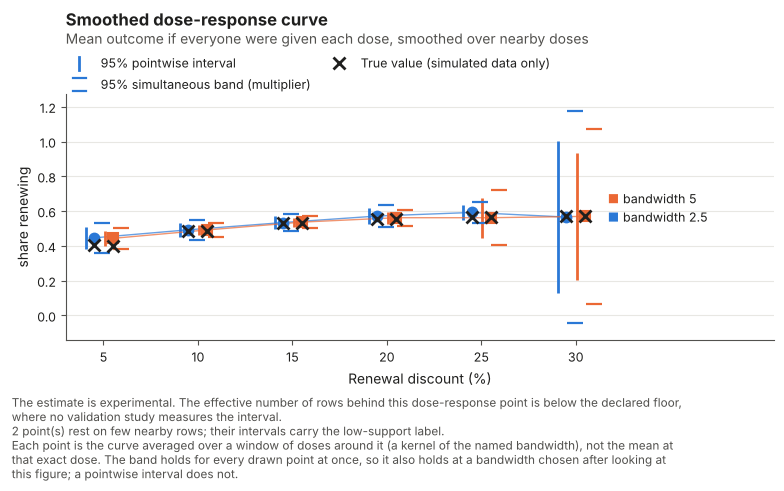

In [6]:
from cleverly.plotting import curve as plot_curve

# The crosses mark the true smoothed curve, which only simulated data have.
figure = plot_curve(
    result,
    outcome_label="share renewing",
    treatment_label="Renewal discount (%)",
    truth=dict(zip(curve.names, table["true"], strict=True)),
)
print(f"band multiplier: {result.band.critical_value:.2f} standard errors")
print(f"pointwise multiplier: {result.band.pointwise_critical_value:.2f} standard errors")

Each bandwidth is one series. The bars are the pointwise 95% intervals, the brackets are the band,
and the crosses are the true values. The band multiplies each standard error by 2.71 instead of
1.96, the price of holding for every point at once. Both series rise from 5% to 20%, and the bars
at 30% stretch across most of the plot.

## Read the band and compare bandwidths

In [7]:
# The band holds for every row at once, so two rows whose bands do not overlap differ.
for h in curve.bandwidths:
    rows = table[table["bandwidth"] == h].set_index("dose")
    low, high = rows.loc[5.0], rows.loc[20.0]
    print(
        f"bandwidth {h:g}: band at 5% off {low['band_lower']:.3f} to {low['band_upper']:.3f}, "
        f"at 20% off {high['band_lower']:.3f} to {high['band_upper']:.3f}, "
        f"separate: {low['band_upper'] < high['band_lower']}"
    )
print()
width = table.assign(width=table["upper"] - table["lower"]).pivot(
    index="dose", columns="bandwidth", values="width"
)
print("width of the pointwise interval, by bandwidth:")
print(width.round(3).to_string())

bandwidth 2.5: band at 5% off 0.360 to 0.533, at 20% off 0.508 to 0.636, separate: False
bandwidth 5: band at 5% off 0.384 to 0.503, at 20% off 0.515 to 0.609, separate: True

width of the pointwise interval, by bandwidth:
bandwidth    2.5    5.0
dose                   
5.0        0.125  0.086
10.0       0.081  0.058
15.0       0.071  0.051
20.0       0.092  0.068
25.0       0.090  0.228
30.0       0.878  0.728


Use the band when you compare discounts, or when you pick a bandwidth after seeing the results.
Two points whose bands do not overlap differ. At bandwidth 5 the band at 5% off ends at 0.503 and
the band at 20% off starts at 0.515. So the smoothed share renewing is higher at 20% off, with 95%
confidence for all the comparisons together. At bandwidth 2.5 the two bands overlap, and reading
bandwidth 5 after seeing that is allowed, because the band covers every declared bandwidth. A
pointwise interval read at a bandwidth picked this way is not adjusted for the choice.

A wider window averages more subscribers, so its interval is usually narrower: 0.051 against
0.071 at 15% off. It also smooths more, and the gap between the average and the curve grows with
the square of the bandwidth where the curve bends. At 25% off the wider window gives the wider
interval, 0.228 against 0.090. It reaches discounts near 30%, where some subscribers got a discount
that the discount model rated very unlikely for them, and those few rows carry very large weights.

## Check the overlap at each dose

In [8]:
support = table[["bandwidth", "dose", "rows", "kish", "low_support"]].copy()
support["status"] = [result.estimate(h, dose).inference for h, dose in curve.pairs]
support["label"] = [result.estimate(h, dose).support.label for h, dose in curve.pairs]
print(support.round(1).to_string(index=False))
print()
print("support floor:", curve.support_floor)
print(
    f"largest move when the integration points double: {result.quadrature_shift:.3f} "
    "standard errors (the fit warns above 0.05)"
)
print("band label:", result.band.support.label)

 bandwidth  dose  rows   kish  low_support                  status        label
       2.5   5.0   434  242.8        False         influence_curve    supported
       2.5  10.0   784  530.7        False         influence_curve    supported
       2.5  15.0   868  644.7        False         influence_curve    supported
       2.5  20.0   778  478.8        False         influence_curve    supported
       2.5  25.0   617  207.6        False         influence_curve    supported
       2.5  30.0   355   30.7         True low_dose_support_plugin experimental
       5.0   5.0   803  357.7        False         influence_curve    supported
       5.0  10.0  1483 1020.6        False         influence_curve    supported
       5.0  15.0  1693 1278.9        False         influence_curve    supported
       5.0  20.0  1555  939.9        False         influence_curve    supported
       5.0  25.0  1202  155.6        False         influence_curve    supported
       5.0  30.0   629   30.0         Tr

Each subscriber in a window gets a weight. It is the window's weight at their discount, divided by
the discount model's chance of that discount for someone like them. `rows` counts the subscribers in
the window, and `kish` is their effective number once the weights are counted, so a few very large
weights make it small. A pair with `kish` below the floor of 50 is flagged in `low_support`, and
its estimate carries the status `low_dose_support_plugin`. Its interval rests on few effective
rows, so the normal approximation behind it is shaky. Both pairs at 30% off are flagged, with
30.7 and 30.0 effective rows out of 355 and 629 subscribers, so read nothing into them.

This check reads the fitted discount model, so it cannot see a confounder that the model leaves
out. At 25% the wider window has fewer effective rows than the narrower one, 155.6 against 207.6,
which is why its interval is wider. The fit also doubles its evaluation points and reports how far
the estimates move: 0.013 standard errors, below the 0.05 at which it warns.

The `label` column says whether a simulation study covers the setup. Every pair above the floor
reads `supported`, because the package's simulation study measured cross-fitted fits of a binary
outcome on unweighted rows. That study used its own simulated data and learners, so the label
says the method was checked, not that this page's models are right. The two flagged pairs read
`experimental`, and so does the band, because it covers them.

## Try to break the result

`cleverly` runs its checks that try to break a result, such as shuffling the treatment, and its
analysis of how strong a missing confounder would have to be on fits made through `CausalStudy`.
`DoseResponseTMLE` is not wired into it and its result has no such methods, so this page cannot
run them. The no-hidden-confounding condition rests on how the engine works; here its rule is
known and logged.

## What we can and can't conclude

For the retention team: raising the renewal discount from 5% to 20% raises the share who renew by
about 12 points at bandwidth 5 (0.443 to 0.562). The band supports a real rise over that range.
Whether discounts deeper than 20% buy more renewals, the data cannot say, though the simulation's
true curve flattens there. To learn about deeper discounts, give a random share of subscribers
discounts between 20% and 40%.

Each number is the renewal share averaged over a window of discounts, and not the share at one
exact discount; `cleverly` gives no interval for the latter (roadmap
[F39](../roadmap.md#f39-unsmoothed-dose-response-curve)). The answer rests on usage and tenure
capturing everything the engine read that also drives renewal, and on both models being
reasonably accurate. This page shows one simulated draw.

## How we know the method works

The package's fast tests check the method's formulas exactly on small made-up populations whose
answer is known. They check that the correction step targets the averaged curve, that the error left after it
vanishes when either model is right, and that deliberately broken versions fail. The Validation
section of the [smoothed dose-response curve](../technical-reference/dose-response.md) reference
lists each check.

A [simulation study](../technical-reference/method-evidence/dose-response.md) then refit the
method on 4,000 simulated datasets for each setting, at 1,000 to 8,000 rows, and passed every
check: the bias and coverage of each interval, and the coverage of the band. It used its own
simulated population and spline models, not this page's learners, and it does not show that the
floor of 50 effective rows is the right cutoff. A comparison with the R package npcausal has not
reported yet.

## Go deeper

### Why doses near the end of the range are harder

In the middle of the range, the window weights nearby discounts symmetrically. It puts more
weight close to the dose and none beyond the bandwidth. Near the end of the range the window is cut
off. To keep the average equal to the curve wherever the curve is a straight line, the weights then
lean to one side and can turn negative.

In [9]:
# The weight each pair puts on nearby discounts depends only on the declaration.
doses = np.linspace(*curve.support, 3001)
middle = curve.weight(5.0, 15.0, doses)
# Dose 32% is the end of the range. It is not declared and is shown for comparison only.
for dose in (15.0, 30.0, 32.0):
    weight = curve.weight(5.0, dose, doses)
    reached = doses[weight != 0.0]
    ratio = np.trapezoid(weight**2, doses) / np.trapezoid(middle**2, doses)
    print(
        f"bandwidth 5, dose {dose:g}%: reaches {reached.min():.1f}% to {reached.max():.1f}%, "
        f"lowest weight {weight.min():+.3f}, total {np.trapezoid(weight, doses):.3f}, "
        f"squared weight {ratio:.1f} times dose 15's"
    )

bandwidth 5, dose 15%: reaches 10.0% to 20.0%, lowest weight +0.000, total 1.000, squared weight 1.0 times dose 15's
bandwidth 5, dose 30%: reaches 25.0% to 32.0%, lowest weight -0.002, total 1.000, squared weight 1.9 times dose 15's
bandwidth 5, dose 32%: reaches 27.0% to 32.0%, lowest weight -0.183, total 1.000, squared weight 7.5 times dose 15's


At 15% the window reaches 10% to 20% and no weight is negative. At 30% it is cut at 32%, and the
lowest weight, -0.002, is barely below zero. At the end of the range itself, 32%, the lowest weight
is -0.183 and the squared weights are 7.5 times those at 15%. An estimate there has a larger
variance, and it can leave the 0-to-1 range of a share. Declaring doses with a margin inside the range
avoids this.

:::{dropdown} Details: the averaged curve
With $\theta(a)$ the share renewing if everyone got discount $a$, the page estimates
$\theta_h(a_0) = \int_D w_{h,a_0}(a)\,\theta(a)\,da$ over the declared range $D$. The weight
$w_{h,a_0}$ is the local-linear equivalent kernel of the Epanechnikov kernel under Lebesgue
measure on $D$. It integrates to one and has zero first moment about $a_0$, so
$\theta_h(a_0) = \theta(a_0)$ wherever $\theta$ is linear on the window, and
$\lvert \theta_h(a_0) - \theta(a_0) \rvert \le \tfrac12 \sup \lvert\theta''\rvert\,
h^2 \int \lvert w \rvert$ where $\theta$ is twice differentiable. In the interior
$w = K_h(\cdot - a_0) \ge 0$; at the end of $D$ it is signed. The
[smoothed dose-response curve](../technical-reference/dose-response.md) reference gives the
influence function, the remainder and the estimator.
:::

## Where to go next

The [smoothed dose-response curve](../technical-reference/dose-response.md) reference states the
quantity, the conditions and what the fit refuses. The section "A curve over a continuous dose" of
the [estimands guide](../user-guide/estimands.md) gives the short version. For a policy that shifts each
subscriber's dose, such as raising every discount by 5 points, see
[three offer policies](interventions.ipynb). For prices set again each month, see
[monthly prices](sequential-pricing.ipynb). The [examples index](index.md) lists every example.